## Let's plot the gordon network atlas

#### # networks that we care about
markdown
#VSC-961484b8
markdown
## Let's plot the gordon network atlas

#### # networks that we care about
#### dim 1: 10, 1, 13, 4
#### dim 3: 3, 1, 11, 4
#### networks = [10, 1, 13, 4]
#### network_map = {10: "CinguloOperc", 1: "Default", 13: "DorsalAttn", 4: "Visual"}

#### '''networks = [3, 1, 11, 4]
#### network_map = {3: "SensoriMouth", 1: "Default", 11: "VentralAttn", 4: "Visual"}'''

<!-- # Define network pairs for each map
network_pairs = [
    (10, 1),  # CinguloOperc + Default
    (1, 11),  # Default + VentralAttn
    (1, 1),  # Default + Default
    (1, 4),  # Default + Visual
    (4, 4),  # Visual + Visual
    (1, 3),  # Default + SensoriMouth
    (11, 4)  # VentralAttn + Visual
]

# Labels
network_map = {
    10: "CinguloOperc",
    1: "Default",
    11: "VentralAttn",
    4: "Visual",
    3: "SensoriMouth",
} -->


In [63]:
# importing the tools we'll use throughout the rest of the script
# sys is system tools, should already be installed
import sys
import json

# pandas is a dataframe-managing library and it's the absolute coolest
import pandas as pd

# numpy is short for "numerical python" and it does math
import numpy as np

# seaborn is a plotting library named after a character from West Wing
# it's kind of like python's ggplot
import seaborn as sns

# nibabel handles nifti images
import nibabel as nib

# os is more system tools, should also already be installed
# we're importing tools for verifying and manipulating file paths/directories
from os.path import join, exists, isdir
from os import makedirs

# nilearn makes the best brain plots
# and their documentation/examples are so, so handy
# https://nilearn.github.io/stable/auto_examples/01_plotting/index.html
from nilearn import plotting, surface, datasets

# matplotlib is the backbone of most python plotting
import matplotlib.pyplot as plt
from scipy.stats import linregress
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap, ListedColormap

# gridspec helps us put lots of panels on one figure
from PIL import Image

from neuromaps import transforms
from neuromaps.datasets import fetch_fslr

from gradec.utils import _zero_medial_wall

from surfplot import Plot
%matplotlib inline

In [64]:
# ---- directories ----
# Finds the project root by walking up from wherever the kernel starts
# (VS Code starts it in code/), so no paths need hand-editing.
# Falls back to ~/Desktop/struc-func-plsc.
from pathlib import Path

def _find_project():
    for d in [Path.cwd(), *Path.cwd().parents]:
        if (d / "gordon_networks_222.nii").exists() and (d / "code").is_dir():
            return d
    return Path.home() / "Desktop" / "struc-func-plsc"

PROJECT = _find_project()
deriv_dir = PROJECT / "derivatives"
fig_dir = deriv_dir / "figures"            # surface-plot PNGs
nii_dir = fig_dir / "gordon-network-rois"  # binary network ROI NIfTIs

# Which PLSC run to plot (a folder in derivatives/) and which PLSC block
RUN = "katie-y4-vars"   # e.g. "katie-baseline-vars", "katie-Y2-vars", "katie-y4-vars"
BLOCK = "rni"           # "rni" or "rnd"
run_dir = deriv_dir / RUN
plsc_dir = run_dir / f"plsc-{BLOCK}"
REG_DIR = plsc_dir / "regression"
gordon_path = PROJECT / "gordon_networks_222.nii"

for d in (fig_dir, nii_dir):
    d.mkdir(parents=True, exist_ok=True)

assert gordon_path.exists(), f"Gordon atlas not found: {gordon_path}"
assert plsc_dir.exists(), f"PLSC outputs not found: {plsc_dir}"
print(f"Project: {PROJECT}\nPLSC:    {plsc_dir}\nFigures: {fig_dir}\nROIs:    {nii_dir}")

Project: /Users/hampson/Desktop/struc-func-plsc
PLSC:    /Users/hampson/Desktop/struc-func-plsc/derivatives/katie-y4-vars/plsc-rni
Figures: /Users/hampson/Desktop/struc-func-plsc/derivatives/figures
ROIs:    /Users/hampson/Desktop/struc-func-plsc/derivatives/figures/gordon-network-rois


In [65]:

CMAP = "Spectral_r"

def plot_surf(nii_img_thr, mask_contours=None, vmax=8, cmap=CMAP):
    map_lh, map_rh = transforms.mni152_to_fslr(nii_img_thr, fslr_density="32k")
    map_lh, map_rh = _zero_medial_wall(
        map_lh,
        map_rh,
        space="fsLR",
        density="32k",
    )
    # midthickness

    surfaces = fetch_fslr(density="32k")
    lh, rh = surfaces["inflated"]
    sulc_lh, sulc_rh = surfaces["sulc"]

    p = Plot(surf_lh=lh, surf_rh=rh, layout="grid")
    p.add_layer({"left": sulc_lh, "right": sulc_rh}, cmap="binary_r", cbar=False)
    p.add_layer(
        {"left": map_lh, "right": map_rh},
        cmap=cmap,
        cbar=False,
        color_range=(-vmax, vmax),
    )
    if mask_contours:
        mask_lh, mask_rh = transforms.mni152_to_fslr(mask_contours, fslr_density="32k")
        mask_lh, mask_rh = _zero_medial_wall(
            mask_lh,
            mask_rh,
            space="fsLR",
            density="32k",
        )
        mask_arr_lh = mask_lh.agg_data()
        mask_arr_rh = mask_rh.agg_data()
        countours_lh = np.zeros_like(mask_arr_lh)
        countours_lh[mask_arr_lh != 0] = 1
        countours_rh = np.zeros_like(mask_arr_rh)
        countours_rh[mask_arr_rh != 0] = 1

        colors = [(0, 0, 0, 0)]
        contour_cmap = ListedColormap(colors, "regions", N=1)
        line_cmap = ListedColormap(["black"], "regions", N=1)
        p.add_layer(
            {"left": countours_lh, "right": countours_rh},
            cmap=line_cmap,
            as_outline=True,
            cbar=False,
        )
        p.add_layer(
            {"left": countours_lh, "right": countours_rh},
            cmap=contour_cmap,
            cbar=False,
        )

    return p.build()

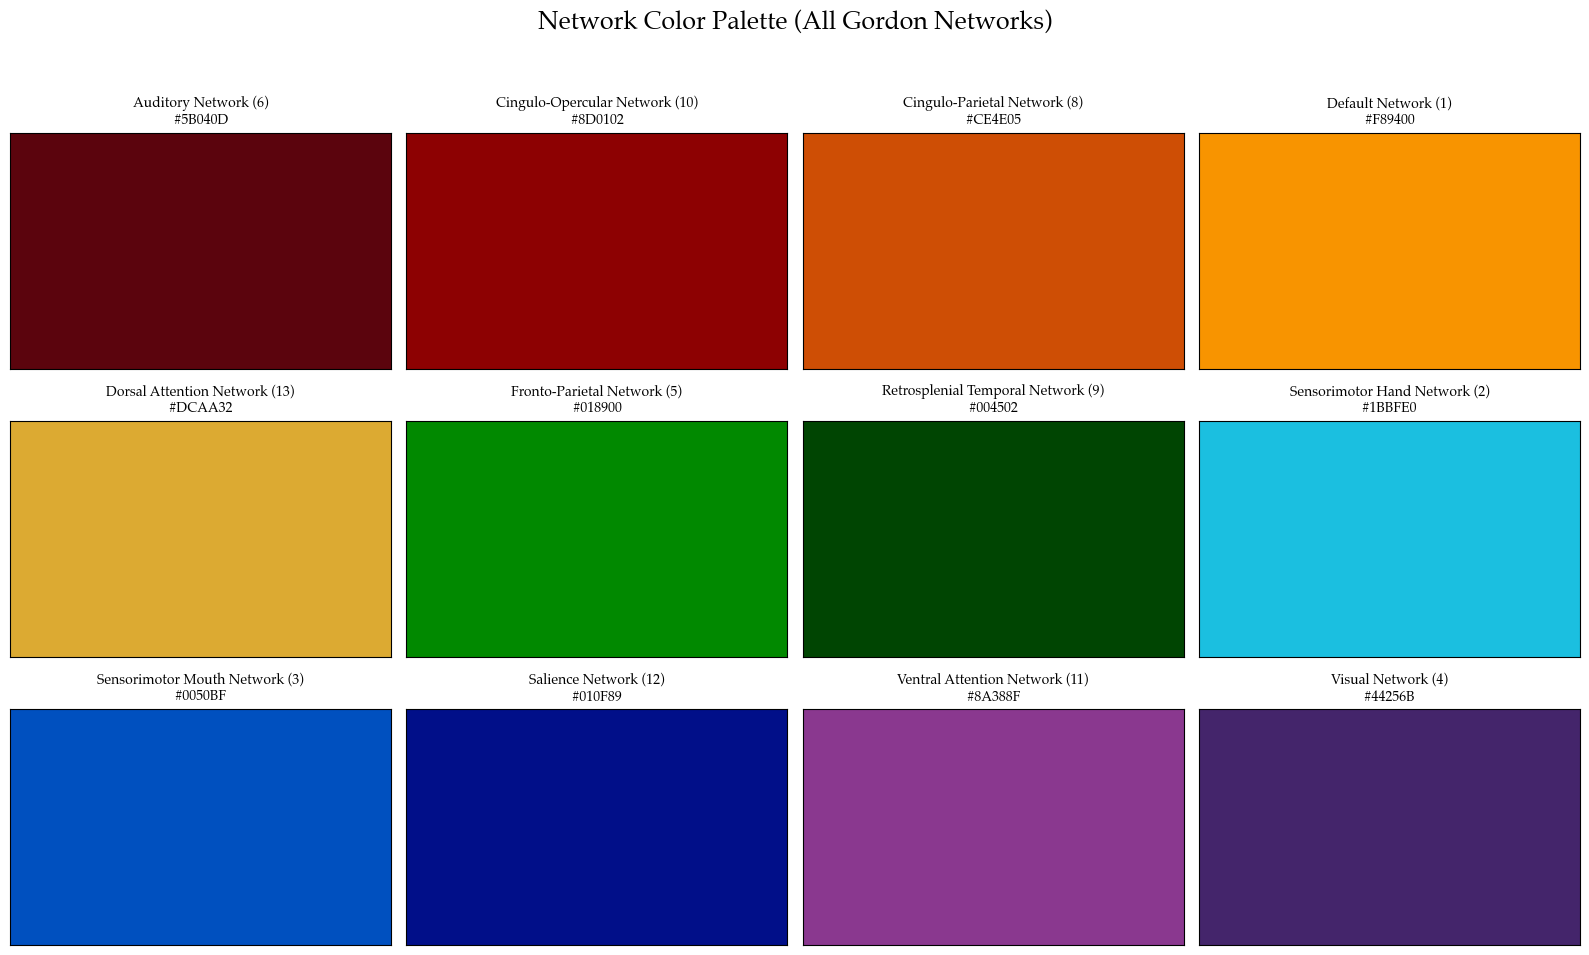

In [66]:
# Define the number of colors in the colormap
num_colors = 1000

# Full set of network hex colors (including non-significant networks)
network_hex = {
    6: "#5B040D",   # Auditory Network
    10: "#8D0102",  # Cingulo-opercular Network
    8: "#CE4E05",   # Cingulo-parietal Network
    1: "#F89400",   # Default Network
    13: "#DCAA32",  # Dorsal Attention Network
    5: "#018900",   # Fronto-parietal Network
    9: "#004502",   # Retrosplenial Temporal Network
    2: "#1BBFE0",   # Sensorimotor Hand Network
    3: "#0050BF",   # Sensorimotor Mouth Network
    12: "#010F89",  # Salience Network
    11: "#8A388F",  # Ventral Attention Network
    4: "#44256B"    # Visual Network
}

# Friendly names for display (keeps the same naming used elsewhere)
network_full_names = {
    6: "Auditory Network",
    10: "Cingulo-Opercular Network",
    8: "Cingulo-Parietal Network",
    1: "Default Network",
    13: "Dorsal Attention Network",
    5: "Fronto-Parietal Network",
    9: "Retrosplenial Temporal Network",
    2: "Sensorimotor Hand Network",
    3: "Sensorimotor Mouth Network",
    12: "Salience Network",
    11: "Ventral Attention Network",
    4: "Visual Network"
}

# Create a LinearSegmentedColormap for each network (solid color mapped)
from matplotlib.colors import LinearSegmentedColormap
cmap_map = {}
for net, hx in network_hex.items():
    cmap_map[net] = LinearSegmentedColormap.from_list(f"net_{net}", [hx, hx], N=num_colors)

# Display all network colormaps in a 3x4 grid
networks_display = [6, 10, 8, 1, 13, 5, 9, 2, 3, 12, 11, 4]

grid_rows = 3
grid_cols = 4
fig, axes = plt.subplots(grid_rows, grid_cols, figsize=(16, 10))
fig.suptitle("Network Color Palette (All Gordon Networks)", fontsize=18, fontweight='bold')

for i, net in enumerate(networks_display):
    row, col = i // grid_cols, i % grid_cols
    ax = axes[row, col]

    # Create simple gradient to show the solid color
    gradient = np.linspace(0, 1, 256).reshape(1, -1)
    ax.imshow(gradient, aspect='auto', cmap=cmap_map[net])
    ax.set_xlim(0, 255)

    # Title shows both network name and hex code for clarity
    ax.set_title(f"{network_full_names[net]} ({net})\n{network_hex[net]}", fontweight='bold', fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [67]:
# fetch once
surf = datasets.fetch_surf_fsaverage()

# load your full Gordon atlas
img = nib.load(gordon_path)
data = img.get_fdata()
affine = img.affine
hdr = img.header

# networks that we care about
# dim 1: 10, 1, 13, 4
# dim 3: 3, 1, 11, 4
networks = [10, 1, 13, 4, 3, 11]

# Reuse canonical full display names (defined in previous cell)
network_map = network_full_names

# Ensure file-safe names include all networks
network_file_map = {
    6: "Auditory",
    10: "CinguloOpercular",
    8: "CinguloParietal",
    1: "Default",
    13: "DorsalAttention",
    5: "FrontoParietal",
    9: "RetrosplenialTemporal",
    2: "SensorimotorHand",
    3: "Sensorimotor",
    12: "Salience",
    11: "VentralAttention",
    4: "Visual",
}

# Define number of colors for the colormaps
num_colors = 256

# Use the existing cmap_map to construct network_colors so plotting calls stay the same
network_colors = {net: cmap_map[net] for net in network_file_map.keys()}

In [68]:
# Save each network as a binary NIfTI ROI
for net in networks:
    network_name = network_map[net]  # Formal name for display
    file_name = network_file_map[net]  # File-safe name for saving
    output_path = join(nii_dir, f"{file_name}_ROI.nii.gz")
    
    # Check if file already exists
    if exists(output_path):
        print(f"✓ {network_name} ROI already exists at {output_path}")
        continue
    
    # Create binary mask: 1 where data==net, 0 elsewhere
    mask_vol = (data == net).astype(np.uint8)
    mask_img = nib.Nifti1Image(mask_vol, affine, hdr)
    
    # Save NIfTI file
    nib.save(mask_img, output_path)
    print(f"✓ Saved {network_name} ROI to {output_path}")

✓ Cingulo-Opercular Network ROI already exists at /Users/hampson/Desktop/struc-func-plsc/derivatives/figures/gordon-network-rois/CinguloOpercular_ROI.nii.gz
✓ Default Network ROI already exists at /Users/hampson/Desktop/struc-func-plsc/derivatives/figures/gordon-network-rois/Default_ROI.nii.gz
✓ Dorsal Attention Network ROI already exists at /Users/hampson/Desktop/struc-func-plsc/derivatives/figures/gordon-network-rois/DorsalAttention_ROI.nii.gz
✓ Visual Network ROI already exists at /Users/hampson/Desktop/struc-func-plsc/derivatives/figures/gordon-network-rois/Visual_ROI.nii.gz
✓ Sensorimotor Mouth Network ROI already exists at /Users/hampson/Desktop/struc-func-plsc/derivatives/figures/gordon-network-rois/Sensorimotor_ROI.nii.gz
✓ Ventral Attention Network ROI already exists at /Users/hampson/Desktop/struc-func-plsc/derivatives/figures/gordon-network-rois/VentralAttention_ROI.nii.gz


✓ Saved Cingulo-Opercular Network surface plot to /Users/hampson/Desktop/struc-func-plsc/derivatives/figures/CinguloOpercular_surface_plot.png


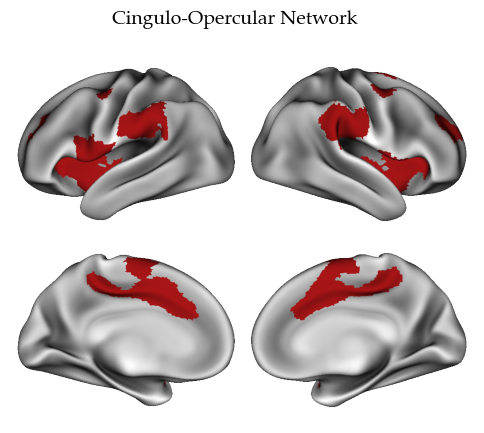

✓ Saved Default Network surface plot to /Users/hampson/Desktop/struc-func-plsc/derivatives/figures/Default_surface_plot.png


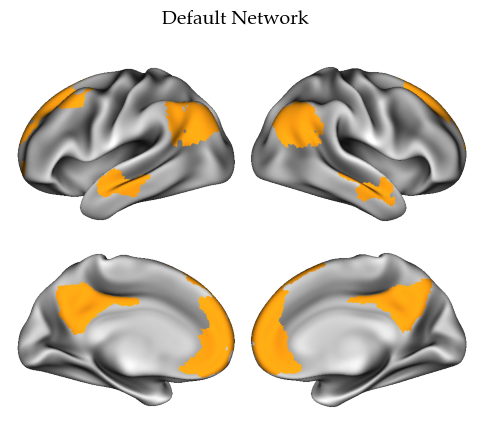

✓ Saved Dorsal Attention Network surface plot to /Users/hampson/Desktop/struc-func-plsc/derivatives/figures/DorsalAttention_surface_plot.png


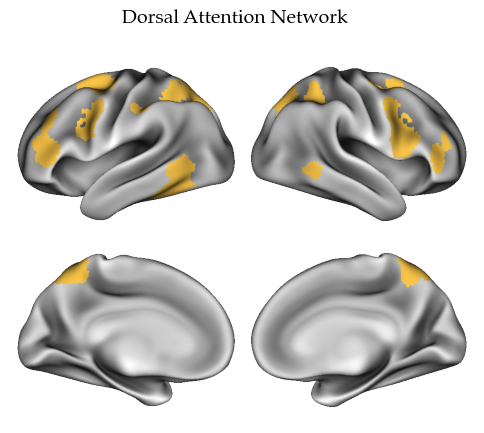

✓ Saved Visual Network surface plot to /Users/hampson/Desktop/struc-func-plsc/derivatives/figures/Visual_surface_plot.png


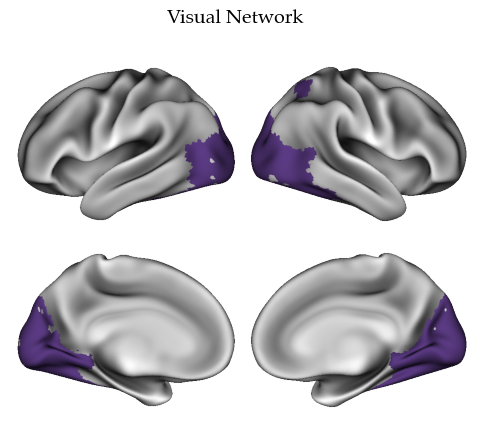

✓ Saved Sensorimotor Mouth Network surface plot to /Users/hampson/Desktop/struc-func-plsc/derivatives/figures/Sensorimotor_surface_plot.png


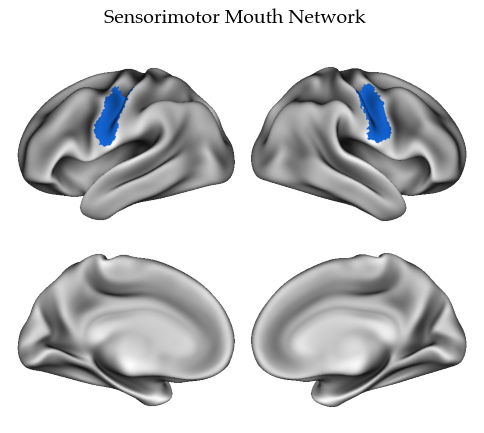

✓ Saved Ventral Attention Network surface plot to /Users/hampson/Desktop/struc-func-plsc/derivatives/figures/VentralAttention_surface_plot.png


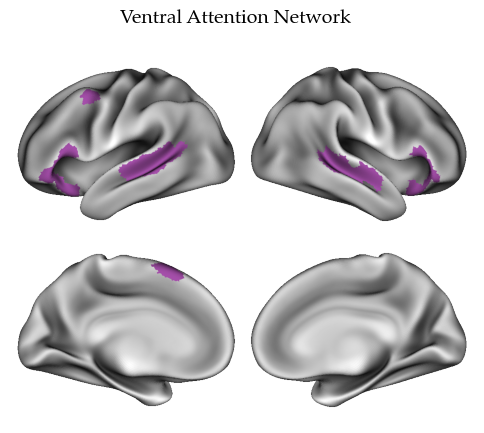

In [69]:
# Load and plot each binary mask using plot_surf function
for net in networks:
    network_name = network_map.get(net, f"Network {net}")  # Formal name for display
    file_name = network_file_map.get(net, f"net_{net}")  # File-safe name for loading
    roi_path = join(nii_dir, f"{file_name}_ROI.nii.gz")

    if not exists(roi_path):
        print(f"⚠ Warning: {roi_path} not found — skipping {network_name}")
        continue

    # Load the saved ROI
    roi_img = nib.load(roi_path)

    # Get the color for this network from the canonical cmap_map (fallback to cmap_map[1] if missing)
    network_cmap = cmap_map.get(net, list(cmap_map.values())[0])

    # Plot using plot_surf function with FSL surfaces
    fig = plot_surf(
        nii_img_thr=roi_img,
        vmax=1,  # Binary mask has values 0 and 1
        cmap=network_cmap,
    )

    # Add title to the plot
    fig.suptitle(f"{network_name}", y=0.95, fontsize=14)

    # Save as high-resolution PNG (using file-safe name)
    output_filename = f"{file_name}_surface_plot.png"
    output_path = join(fig_dir, output_filename)
    fig.savefig(output_path, dpi=300, bbox_inches='tight', 
                facecolor='white', edgecolor='none')
    print(f"✓ Saved {network_name} surface plot to {output_path}")

    plt.show()


sizeof_hdr should be 348; set sizeof_hdr to 348
sizeof_hdr should be 348; set sizeof_hdr to 348


Creating combined network visualizations...

Creating combined visualization: Cingulo-Opercular Network + Default Network
✓ Saved Cingulo-Opercular Network + Default Network surface plot to /Users/hampson/Desktop/struc-func-plsc/derivatives/figures/CinguloOpercular_Default_combined_surface_plot.png


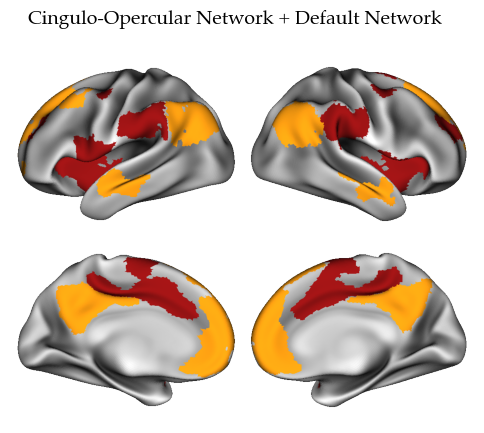

sizeof_hdr should be 348; set sizeof_hdr to 348
sizeof_hdr should be 348; set sizeof_hdr to 348



Creating combined visualization: Default Network + Dorsal Attention Network
✓ Saved Default Network + Dorsal Attention Network surface plot to /Users/hampson/Desktop/struc-func-plsc/derivatives/figures/Default_DorsalAttention_combined_surface_plot.png


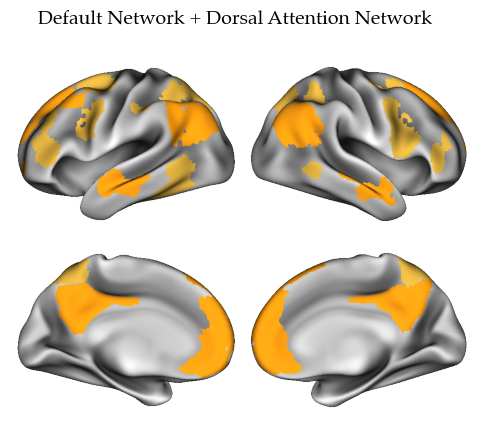

sizeof_hdr should be 348; set sizeof_hdr to 348
sizeof_hdr should be 348; set sizeof_hdr to 348



Creating combined visualization: Default Network + Visual Network
✓ Saved Default Network + Visual Network surface plot to /Users/hampson/Desktop/struc-func-plsc/derivatives/figures/Default_Visual_combined_surface_plot.png


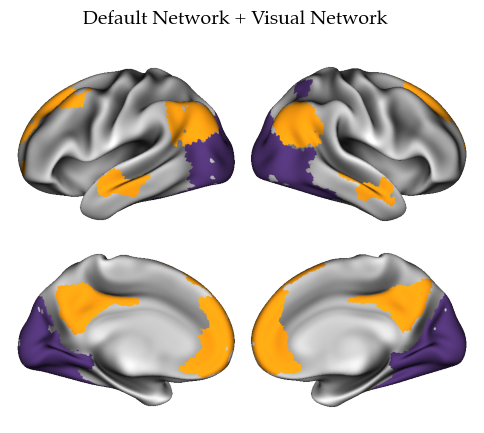

sizeof_hdr should be 348; set sizeof_hdr to 348
sizeof_hdr should be 348; set sizeof_hdr to 348



Creating combined visualization: Default Network + Sensorimotor Mouth Network
✓ Saved Default Network + Sensorimotor Mouth Network surface plot to /Users/hampson/Desktop/struc-func-plsc/derivatives/figures/Default_Sensorimotor_combined_surface_plot.png


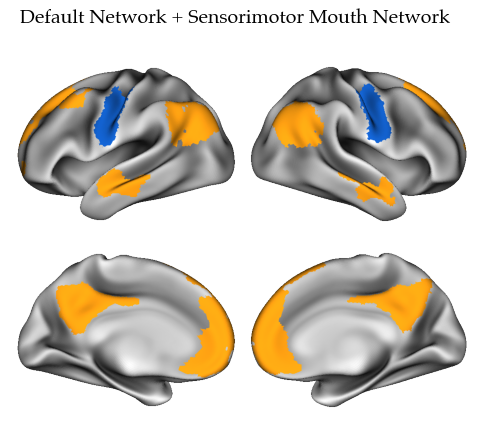

sizeof_hdr should be 348; set sizeof_hdr to 348



Creating combined visualization: Ventral Attention Network + Visual Network


sizeof_hdr should be 348; set sizeof_hdr to 348


✓ Saved Ventral Attention Network + Visual Network surface plot to /Users/hampson/Desktop/struc-func-plsc/derivatives/figures/VentralAttention_Visual_combined_surface_plot.png


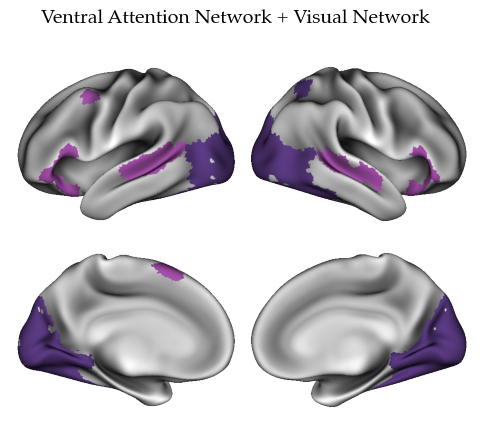

In [70]:
# Create combined visualizations for multiple network pairs
print("Creating combined network visualizations...")


# Define all network pairs to visualize
network_pairs = [
    (10, 1),   # Cingulo-Opercular + Default
    (1, 13),   # Default + Dorsal Attention
    (1, 4),    # Default + Visual
    (1, 3),    # Default + Sensorimotor
    (11, 4)    # Ventral Attention + Visual
]

# Get surfaces once
surfaces = fetch_fslr(density="32k")
lh, rh = surfaces["inflated"]
sulc_lh, sulc_rh = surfaces["sulc"]

for net1, net2 in network_pairs:
    print(f"\nCreating combined visualization: {network_map[net1]} + {network_map[net2]}")
    
    # Create individual binary masks for each network
    net1_volume = np.zeros_like(data)
    net2_volume = np.zeros_like(data)
    
    net1_volume[data == net1] = 1
    net2_volume[data == net2] = 1
    
    # Create NIfTI images for each network
    net1_img = nib.Nifti1Image(net1_volume, affine, hdr)
    net2_img = nib.Nifti1Image(net2_volume, affine, hdr)
    
    # Transform both networks to surface space
    net1_lh, net1_rh = transforms.mni152_to_fslr(net1_img, fslr_density="32k")
    net1_lh, net1_rh = _zero_medial_wall(net1_lh, net1_rh, space="fsLR", density="32k")
    
    net2_lh, net2_rh = transforms.mni152_to_fslr(net2_img, fslr_density="32k")
    net2_lh, net2_rh = _zero_medial_wall(net2_lh, net2_rh, space="fsLR", density="32k")
    
    # Create plot with multiple layers
    p = Plot(surf_lh=lh, surf_rh=rh, layout="grid")
    
    # Add sulcal depth as base layer
    p.add_layer({"left": sulc_lh, "right": sulc_rh}, cmap="binary_r", cbar=False)
    
    # Add first network layer
    p.add_layer(
        {"left": net1_lh, "right": net1_rh},
        cmap=network_colors[net1],
        cbar=False,
        color_range=(0, 1),
    )
    
    # Add second network layer
    p.add_layer(
        {"left": net2_lh, "right": net2_rh},
        cmap=network_colors[net2],
        cbar=False,
        color_range=(0, 1),
    )
    
    # Build the figure
    fig = p.build()
    
    # Create title with network names and colors
    net1_name = network_map[net1].split(' (')[0]  # Remove abbreviation
    net2_name = network_map[net2].split(' (')[0]  # Remove abbreviation
    
    fig.suptitle(f"{net1_name} + {net2_name}", 
                 y=0.95, fontsize=14, fontweight='bold')
    
    # Save the combined visualization
    net1_file = network_file_map[net1]
    net2_file = network_file_map[net2]
    combined_filename = f"{net1_file}_{net2_file}_combined_surface_plot.png"
    combined_path = join(fig_dir, combined_filename)
    fig.savefig(combined_path, dpi=300, bbox_inches='tight', 
                facecolor='white', edgecolor='none')
    print(f"✓ Saved {net1_name} + {net2_name} surface plot to {combined_path}")
    
    plt.show()

Creating composite image from individual PNG files...


/var/folders/1c/1nt_yqzx44j45yghb2dqwrbh0000gp/T/ipykernel_19553/583908003.py:26: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


✓ Saved composite 2x3 grid image to /Users/hampson/Desktop/struc-func-plsc/derivatives/figures/Significant_Gordon_Nets.png


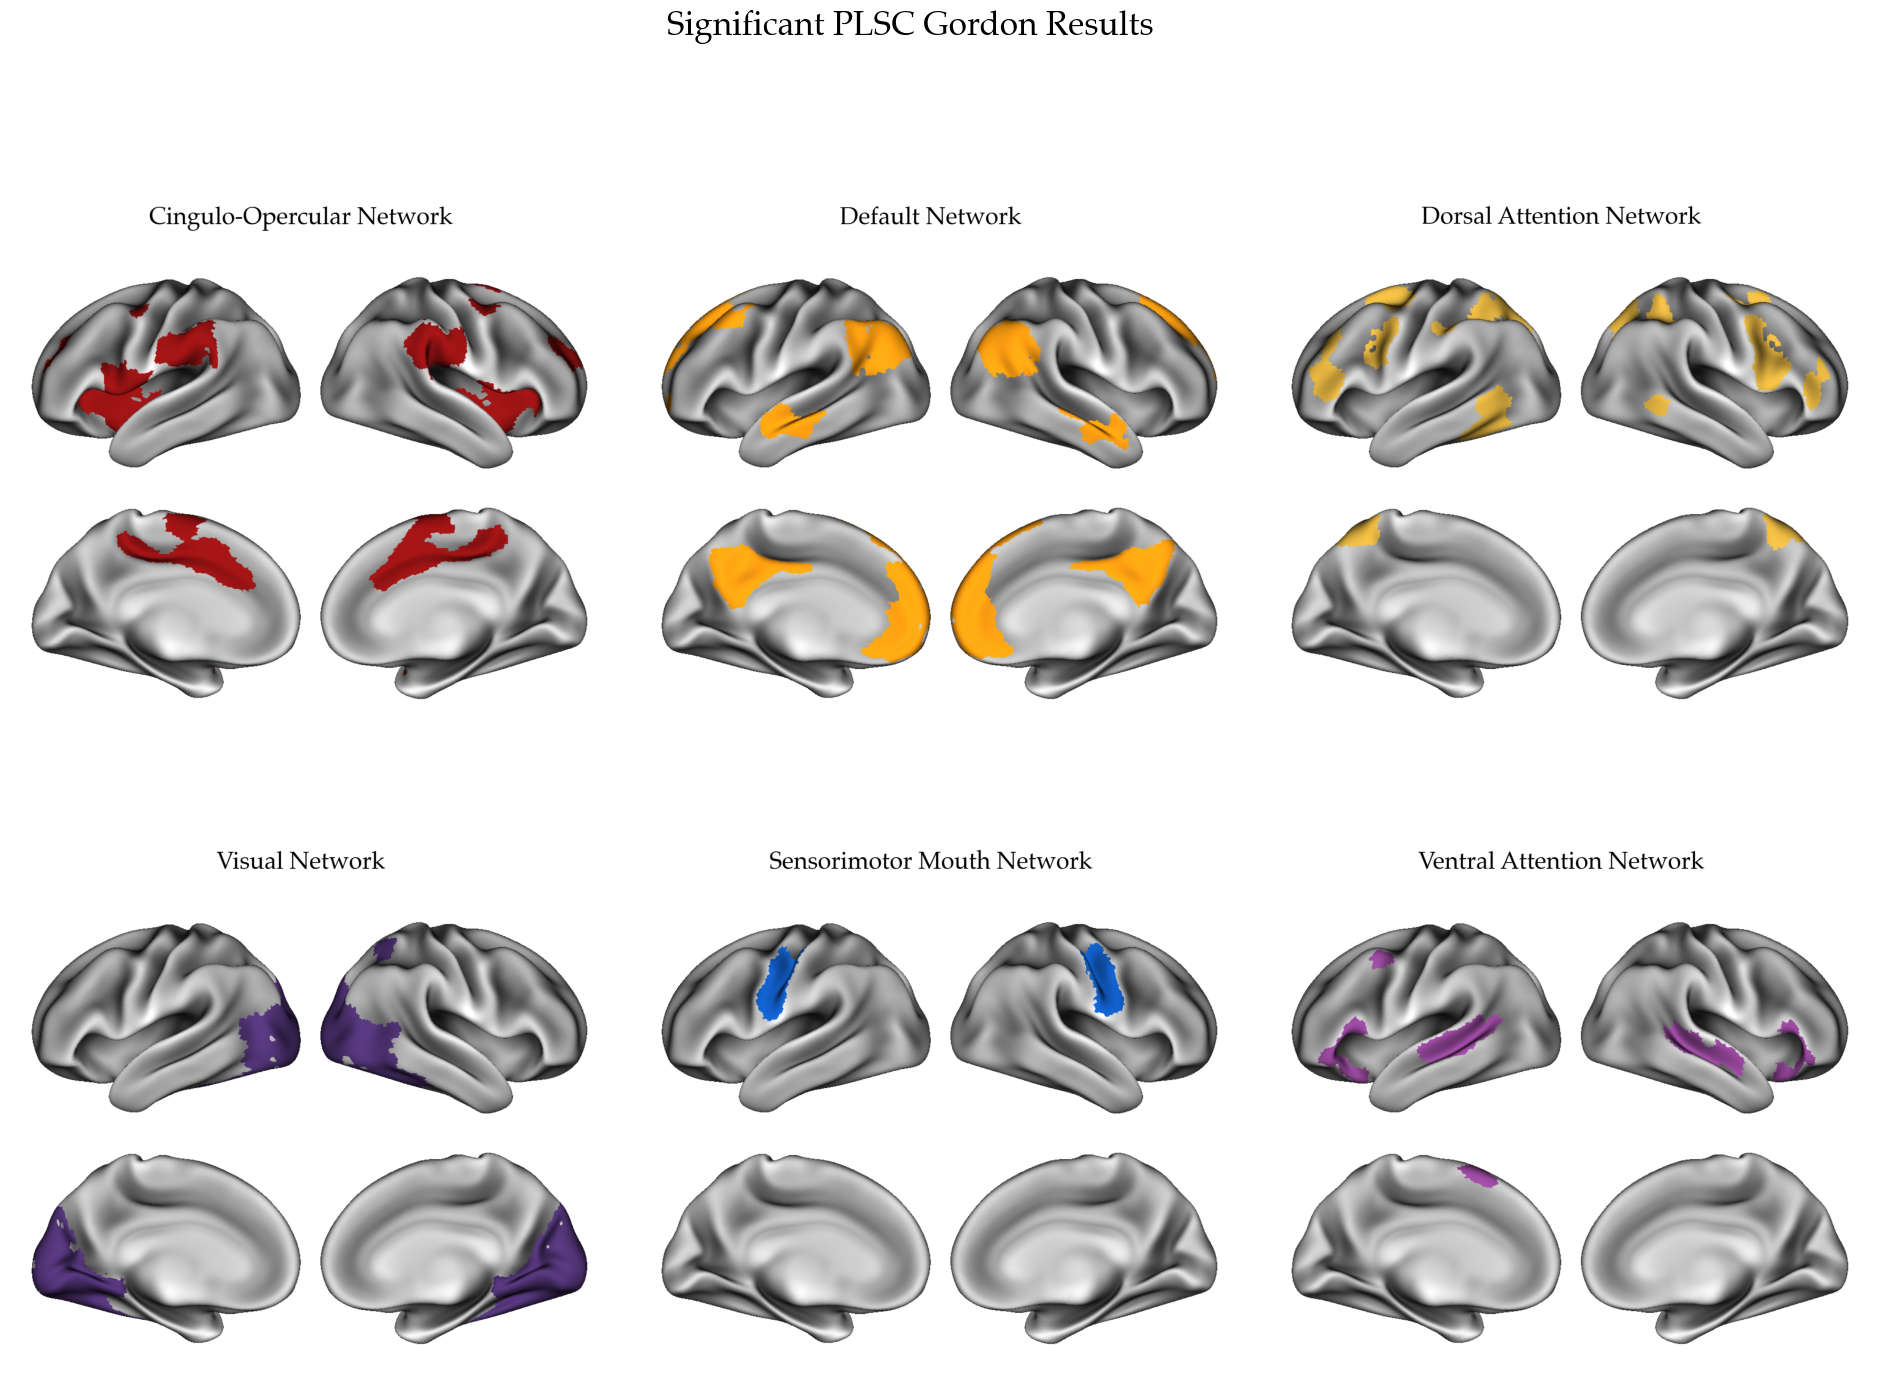

In [71]:
# Combine the 6 individual PNG files into a single 2x3 grid image

print("Creating composite image from individual PNG files...")

# Create a figure with 2x3 subplots
fig = plt.figure(figsize=(24, 16))
fig.suptitle("Significant PLSC Gordon Results", fontsize=24, fontweight='bold')

# Create grid
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.1, wspace=0.05)

# Load and display each PNG image
for i, net in enumerate(networks):
    network_name = network_map[net]  # Formal name for display
    file_name = network_file_map[net]  # File-safe name for loading
    png_path = join(fig_dir, f"{file_name}_surface_plot.png")
    
    row, col = i // 3, i % 3
    ax = fig.add_subplot(gs[row, col])

    # Load the PNG image
    img = Image.open(png_path)
    ax.imshow(img)
    ax.axis('off')  # Remove axes for cleaner look

plt.tight_layout()

# Save the composite image
composite_filename = "Significant_Gordon_Nets.png"
composite_path = join(fig_dir, composite_filename)
fig.savefig(composite_path, dpi=300, bbox_inches='tight', 
            facecolor='white', edgecolor='none')
print(f"✓ Saved composite 2x3 grid image to {composite_path}")

plt.show()

Creating custom composite images...

Creating networks-dim1.png...
✓ Added CinguloOpercular_Default_combined_surface_plot.png to top row
✓ Added Default_surface_plot.png to top row
✓ Added Default_DorsalAttention_combined_surface_plot.png to bottom row
✓ Added Default_Visual_combined_surface_plot.png to bottom row
✓ Added Visual_surface_plot.png to bottom row


/var/folders/1c/1nt_yqzx44j45yghb2dqwrbh0000gp/T/ipykernel_19553/1375989498.py:55: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


✓ Saved networks-dim1.png to /Users/hampson/Desktop/struc-func-plsc/derivatives/figures/networks-dim1.png


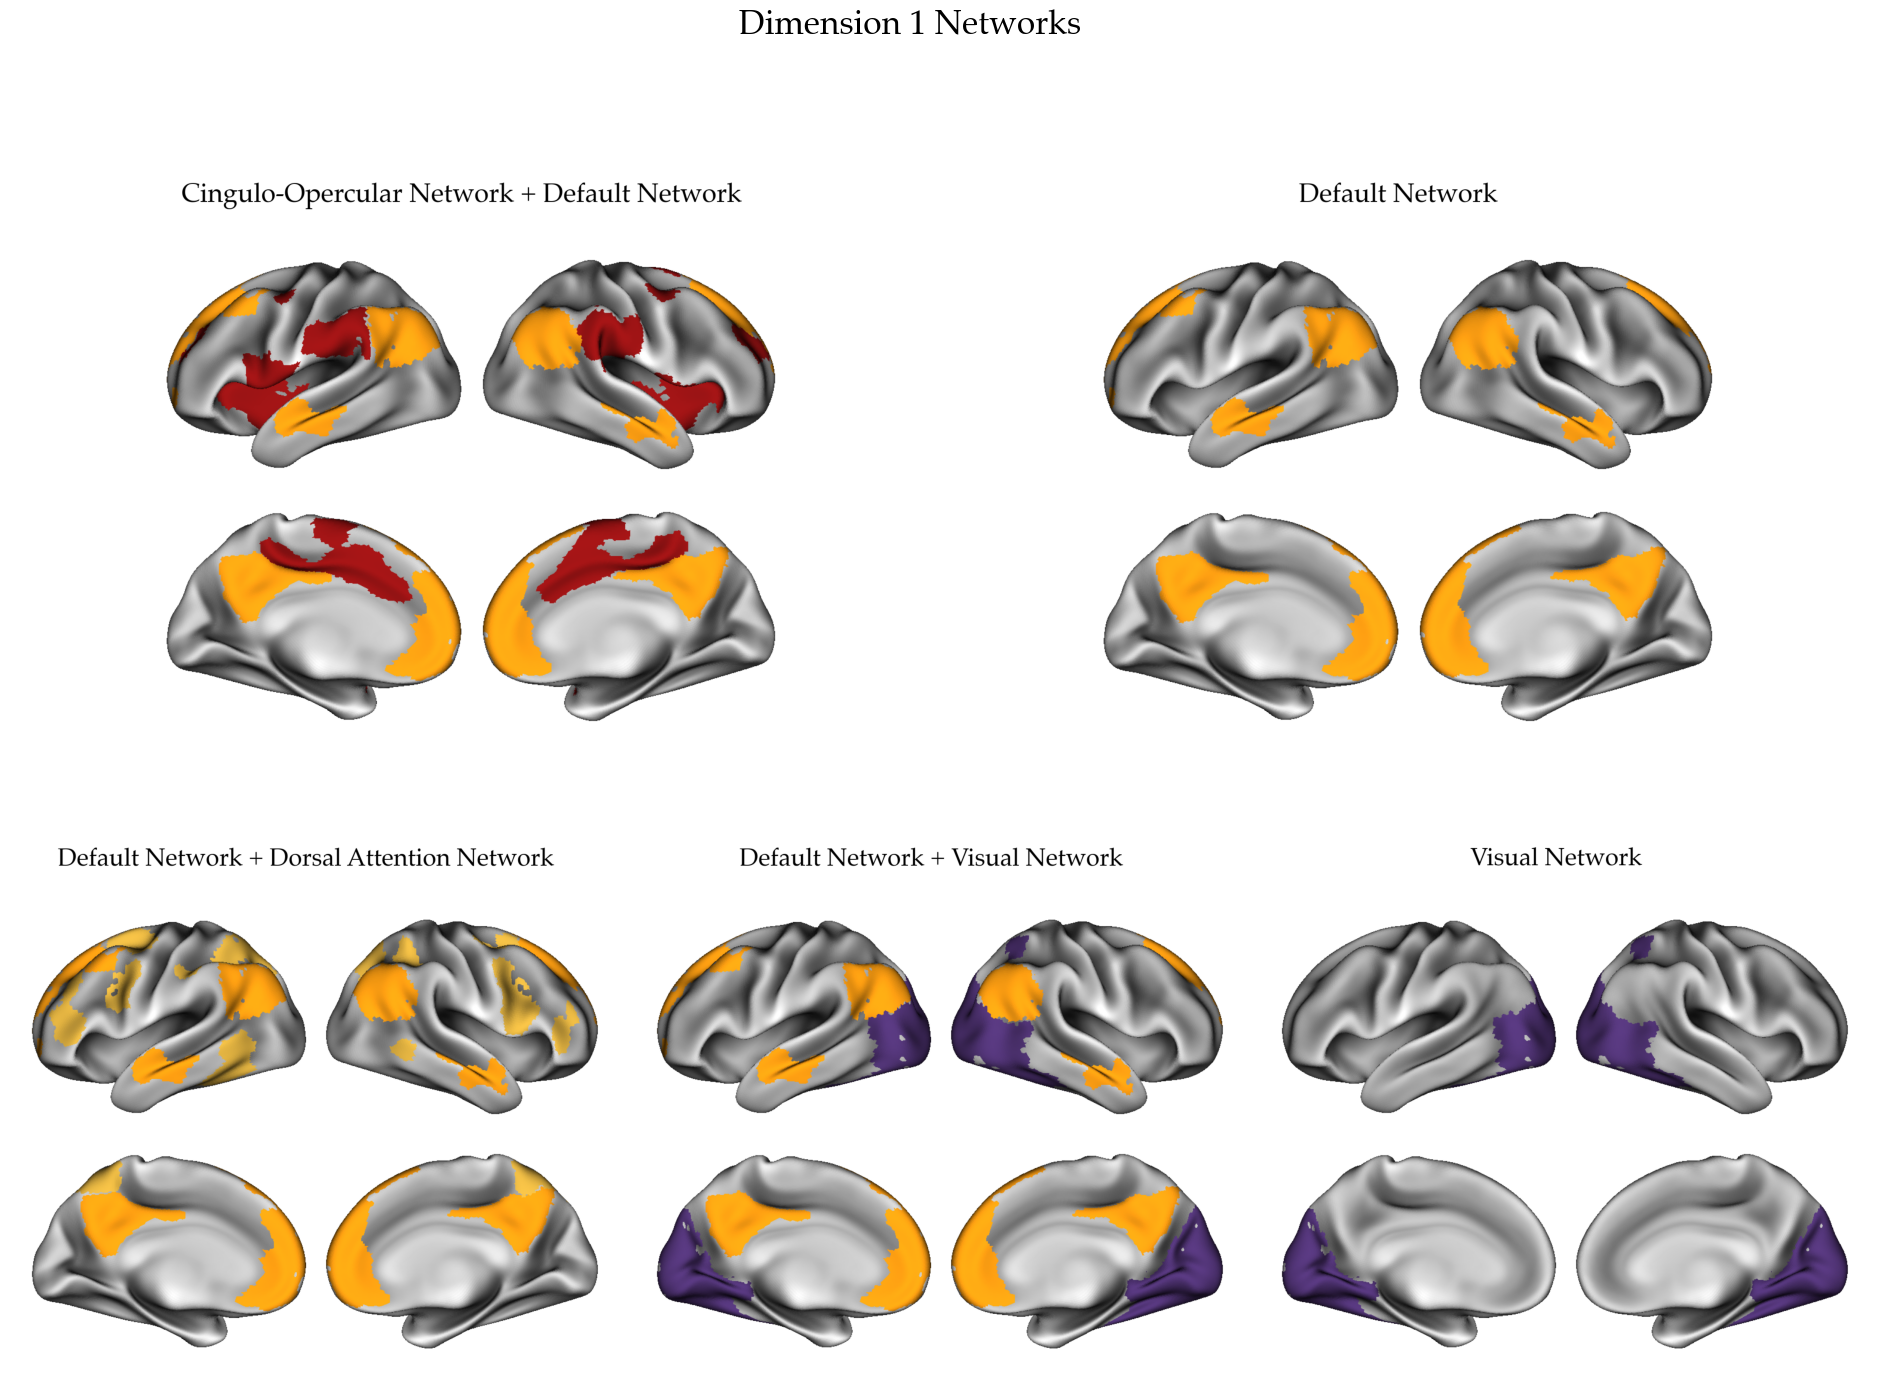


Creating networks-dim3.png...
✓ Added Default_Sensorimotor_combined_surface_plot.png
✓ Added VentralAttention_Visual_combined_surface_plot.png


/var/folders/1c/1nt_yqzx44j45yghb2dqwrbh0000gp/T/ipykernel_19553/1375989498.py:85: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


✓ Saved networks-dim3.png to /Users/hampson/Desktop/struc-func-plsc/derivatives/figures/networks-dim3.png


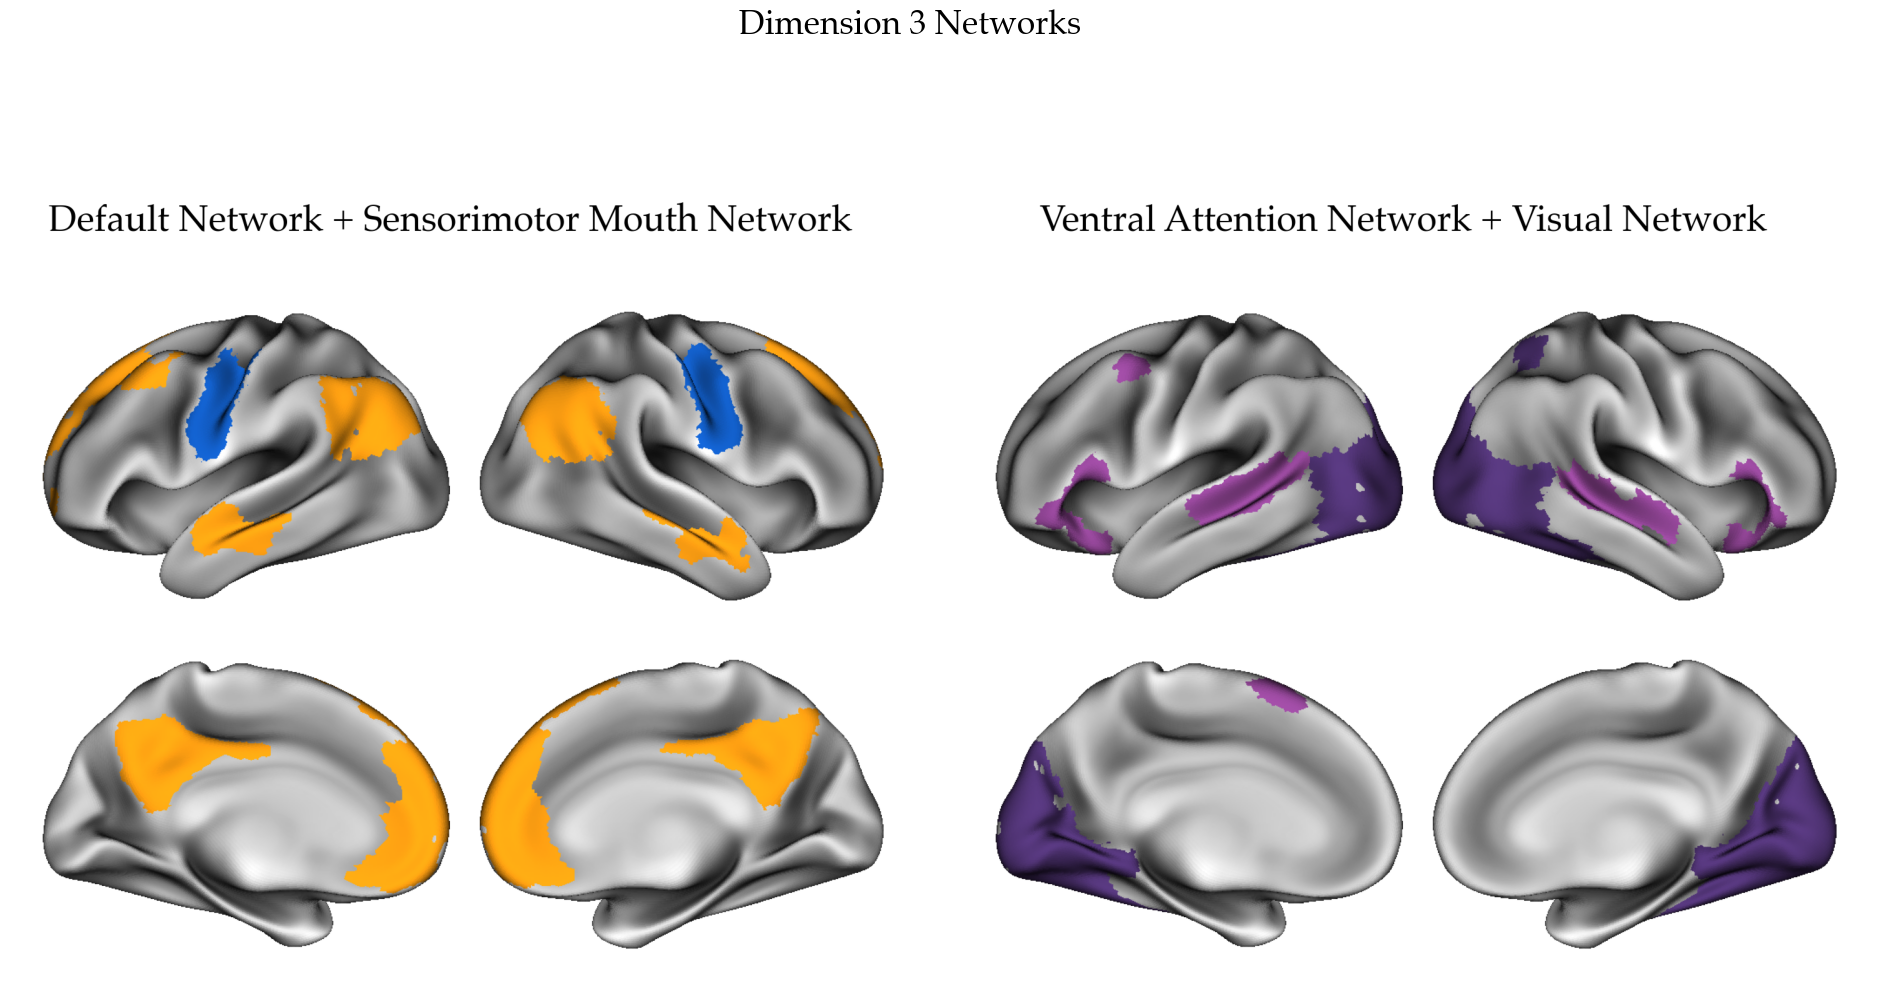


✓ Completed creation of both custom composite images!


In [72]:
# Create custom composite images for dimension 1 and dimension 3 networks
print("Creating custom composite images...")

# Define the images for networks-dim1.png (2x3 layout: 2 on top, 3 on bottom)
dim1_images = [
    "CinguloOpercular_Default_combined_surface_plot.png",  # Top row, left
    "Default_surface_plot.png",                           # Top row, right
    "Default_DorsalAttention_combined_surface_plot.png",  # Bottom row, left
    "Default_Visual_combined_surface_plot.png",           # Bottom row, center
    "Visual_surface_plot.png"                             # Bottom row, right
]

# Define the images for networks-dim3.png (1x2 layout: 2 side by side)
dim3_images = [
    "Default_Sensorimotor_combined_surface_plot.png",     # Left
    "VentralAttention_Visual_combined_surface_plot.png"   # Right
]

# Create networks-dim1.png with 2x3 layout
print("\nCreating networks-dim1.png...")
fig = plt.figure(figsize=(24, 16))
fig.suptitle("Dimension 1 Networks", fontsize=24, fontweight='bold')

# Create custom grid: 2 columns for top row, 3 columns for bottom row
gs = gridspec.GridSpec(2, 6, figure=fig, hspace=0.1, wspace=0.05)

# Top row: 2 images (spanning 3 columns each)
for i in range(2):
    img_path = join(fig_dir, dim1_images[i])
    if exists(img_path):
        col_start = i * 3
        col_end = col_start + 3
        ax = fig.add_subplot(gs[0, col_start:col_end])
        img = Image.open(img_path)
        ax.imshow(img)
        ax.axis('off')
        print(f"✓ Added {dim1_images[i]} to top row")
    else:
        print(f"⚠ Warning: {img_path} not found")

# Bottom row: 3 images (spanning 2 columns each)
for i in range(3):
    img_path = join(fig_dir, dim1_images[i + 2])
    if exists(img_path):
        col_start = i * 2
        col_end = col_start + 2
        ax = fig.add_subplot(gs[1, col_start:col_end])
        img = Image.open(img_path)
        ax.imshow(img)
        ax.axis('off')
        print(f"✓ Added {dim1_images[i + 2]} to bottom row")
    else:
        print(f"⚠ Warning: {img_path} not found")

plt.tight_layout()

# Save networks-dim1.png
dim1_filename = "networks-dim1.png"
dim1_path = join(fig_dir, dim1_filename)
fig.savefig(dim1_path, dpi=300, bbox_inches='tight', 
            facecolor='white', edgecolor='none')
print(f"✓ Saved {dim1_filename} to {dim1_path}")
plt.show()

# Create networks-dim3.png with 1x2 layout
print("\nCreating networks-dim3.png...")
fig = plt.figure(figsize=(24, 12))
fig.suptitle("Dimension 3 Networks", fontsize=24, fontweight='bold')

# Create grid for 2 side-by-side images
gs = gridspec.GridSpec(1, 2, figure=fig, hspace=0.1, wspace=0.05)

# Add the 2 images side by side
for i, img_name in enumerate(dim3_images):
    img_path = join(fig_dir, img_name)
    if exists(img_path):
        ax = fig.add_subplot(gs[0, i])
        img = Image.open(img_path)
        ax.imshow(img)
        ax.axis('off')
        print(f"✓ Added {img_name}")
    else:
        print(f"⚠ Warning: {img_path} not found")

plt.tight_layout()

# Save networks-dim3.png
dim3_filename = "networks-dim3.png"
dim3_path = join(fig_dir, dim3_filename)
fig.savefig(dim3_path, dpi=300, bbox_inches='tight', 
            facecolor='white', edgecolor='none')
print(f"✓ Saved {dim3_filename} to {dim3_path}")
plt.show()

print("\n✓ Completed creation of both custom composite images!")

sizeof_hdr should be 348; set sizeof_hdr to 348


Creating combined multi-network visualization...
Adding Default Network to combined visualization...
Adding Sensorimotor Mouth Network to combined visualization...
Adding Ventral Attention Network to combined visualization...
Adding Visual Network to combined visualization...


sizeof_hdr should be 348; set sizeof_hdr to 348


Adding layer for Default Network


sizeof_hdr should be 348; set sizeof_hdr to 348
sizeof_hdr should be 348; set sizeof_hdr to 348


Adding layer for Sensorimotor Mouth Network
Adding layer for Ventral Attention Network
Adding layer for Visual Network


sizeof_hdr should be 348; set sizeof_hdr to 348


✓ Saved combined surface plot to /Users/hampson/Desktop/struc-func-plsc/derivatives/figures/Default_Sensorimotor_VentralAttention_Visual_dim3.png


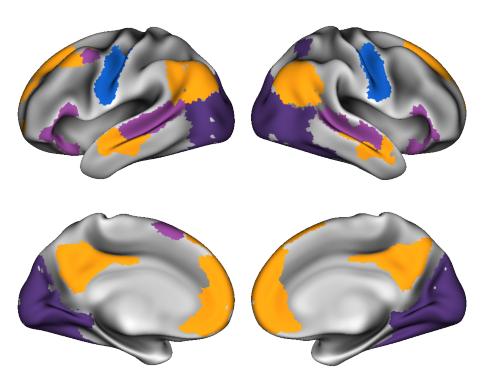

In [73]:
print("Creating combined multi-network visualization...")

# Define the networks to include in the combined plot
networks_to_combine = [1, 3, 11, 4]  # Default, Sensorimotor, Ventral Attention, Visual

# Get surfaces once
surfaces = fetch_fslr(density="32k")
lh, rh = surfaces["inflated"]
sulc_lh, sulc_rh = surfaces["sulc"]

# Initialize empty arrays for combined volume
combined_volume = np.zeros_like(data)

# Loop through each network and add it to the combined mask
for net in networks_to_combine:
    print(f"Adding {network_map[net]} to combined visualization...")
    mask = np.zeros_like(data)
    mask[data == net] = 1
    combined_volume += mask  # Overlapping areas will be >1, which is fine for now

# Transform combined volume to surface space
combined_img = nib.Nifti1Image(combined_volume, affine, hdr)
lh_data, rh_data = transforms.mni152_to_fslr(combined_img, fslr_density="32k")
lh_data, rh_data = _zero_medial_wall(lh_data, rh_data, space="fsLR", density="32k")

# Create base plot
p = Plot(surf_lh=lh, surf_rh=rh, layout="grid")

# Add sulcal depth as background
p.add_layer({"left": sulc_lh, "right": sulc_rh}, cmap="binary_r", cbar=False)

# Add each network as a separate overlay layer
for net in networks_to_combine:
    print(f"Adding layer for {network_map[net]}")
    
    mask = np.zeros_like(data)
    mask[data == net] = 1
    mask_img = nib.Nifti1Image(mask, affine, hdr)
    lh_net, rh_net = transforms.mni152_to_fslr(mask_img, fslr_density="32k")
    lh_net, rh_net = _zero_medial_wall(lh_net, rh_net, space="fsLR", density="32k")
    
    p.add_layer(
        {"left": lh_net, "right": rh_net},
        cmap=network_colors[net],
        cbar=False,
        color_range=(0, 1),
    )

# Build and label figure
fig = p.build()

# Create title from network names
network_names = [network_map[n].split(' (')[0] for n in networks_to_combine]
#title_str = " + ".join(network_names)

#fig.suptitle(title_str, y=0.95, fontsize=14, fontweight='bold')

# Save figure
combined_filename = "_".join([network_file_map[n] for n in networks_to_combine]) + "_dim3.png"
combined_path = join(fig_dir, combined_filename)
fig.savefig(combined_path, dpi=300, bbox_inches='tight', facecolor='white', edgecolor='none')

print(f"✓ Saved combined surface plot to {combined_path}")

plt.show()


Creating combined multi-network visualization with all gordon networks...
Adding Default Network to combined visualization...
Adding Sensorimotor Mouth Network to combined visualization...


sizeof_hdr should be 348; set sizeof_hdr to 348
sizeof_hdr should be 348; set sizeof_hdr to 348
sizeof_hdr should be 348; set sizeof_hdr to 348


Adding Ventral Attention Network to combined visualization...
Adding Visual Network to combined visualization...
Adding layer for Default Network
Adding layer for Sensorimotor Mouth Network


sizeof_hdr should be 348; set sizeof_hdr to 348
sizeof_hdr should be 348; set sizeof_hdr to 348


Adding layer for Ventral Attention Network
Adding layer for Visual Network
✓ Saved combined surface plot to /Users/hampson/Desktop/struc-func-plsc/derivatives/figures/Default_Sensorimotor_VentralAttention_Visual_dim3.png


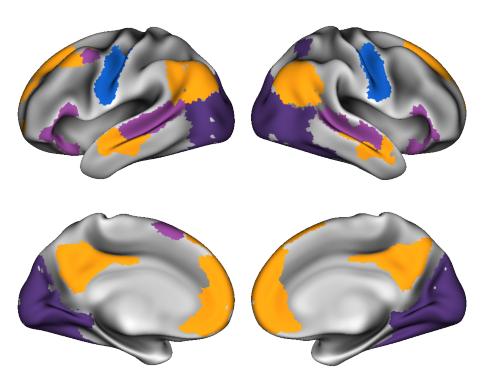

In [74]:
print("Creating combined multi-network visualization with all gordon networks...")

# Define the networks to include in the combined plot
networks_to_combine = [1, 3, 11, 4]  

# Get surfaces once
surfaces = fetch_fslr(density="32k")
lh, rh = surfaces["inflated"]
sulc_lh, sulc_rh = surfaces["sulc"]

# Initialize empty arrays for combined volume
combined_volume = np.zeros_like(data)

# Loop through each network and add it to the combined mask
for net in networks_to_combine:
    print(f"Adding {network_map[net]} to combined visualization...")
    mask = np.zeros_like(data)
    mask[data == net] = 1
    combined_volume += mask  # Overlapping areas will be >1, which is fine for now

# Transform combined volume to surface space
combined_img = nib.Nifti1Image(combined_volume, affine, hdr)
lh_data, rh_data = transforms.mni152_to_fslr(combined_img, fslr_density="32k")
lh_data, rh_data = _zero_medial_wall(lh_data, rh_data, space="fsLR", density="32k")

# Create base plot
p = Plot(surf_lh=lh, surf_rh=rh, layout="grid")

# Add sulcal depth as background
p.add_layer({"left": sulc_lh, "right": sulc_rh}, cmap="binary_r", cbar=False)

# Add each network as a separate overlay layer
for net in networks_to_combine:
    print(f"Adding layer for {network_map[net]}")
    
    mask = np.zeros_like(data)
    mask[data == net] = 1
    mask_img = nib.Nifti1Image(mask, affine, hdr)
    lh_net, rh_net = transforms.mni152_to_fslr(mask_img, fslr_density="32k")
    lh_net, rh_net = _zero_medial_wall(lh_net, rh_net, space="fsLR", density="32k")
    
    p.add_layer(
        {"left": lh_net, "right": rh_net},
        cmap=network_colors[net],
        cbar=False,
        color_range=(0, 1),
    )

# Build and label figure
fig = p.build()

# Create title from network names
network_names = [network_map[n].split(' (')[0] for n in networks_to_combine]
#title_str = " + ".join(network_names)

#fig.suptitle(title_str, y=0.95, fontsize=14, fontweight='bold')

# Save figure
combined_filename = "_".join([network_file_map[n] for n in networks_to_combine]) + "_dim3.png"
combined_path = join(fig_dir, combined_filename)
fig.savefig(combined_path, dpi=300, bbox_inches='tight', facecolor='white', edgecolor='none')

print(f"✓ Saved combined surface plot to {combined_path}")

plt.show()


## Plotting the rs-FC bootstrap ratios on one brain

Each rs-FC feature is a Gordon network pair (e.g. `def__doa` = Default–Dorsal Attention).
A connection's bootstrap ratio (BR) is assigned to **both** of its networks, and each
network is coloured by the mean BR across its connections.

In [75]:
DIM = 1  # which dimension to plot

# PLSC outputs (loadings + bootstrap ratios), from 1b-plsc-clean.Rmd
rsfc_bootdf = pd.read_csv(plsc_dir / "rsfc_P-components.csv")
struct_bootdf = pd.read_csv(plsc_dir / f"{BLOCK}_Q-components.csv")
sig_dims = pd.read_csv(plsc_dir / "significant_dimensions.csv")

print(f"{RUN} / plsc-{BLOCK}: significant dimensions = {sig_dims['dimension'].tolist()}")
print(rsfc_bootdf[["Unnamed: 0", f"BR_Dim{DIM}"]].head())

katie-y4-vars / plsc-rni: significant dimensions = [1, 2, 3, 4, 5, 6, 7, 8]
                                Unnamed: 0   BR_Dim1
0  mr_y_rsfmri__corr__gpnet__aud__aud_mean -5.139798
1  mr_y_rsfmri__corr__gpnet__aud__cio_mean  2.816543
2  mr_y_rsfmri__corr__gpnet__aud__cip_mean  2.813427
3  mr_y_rsfmri__corr__gpnet__aud__def_mean  1.530272
4  mr_y_rsfmri__corr__gpnet__aud__doa_mean  5.636015


In [76]:
# ABCD Gordon network abbreviation -> value in gordon_networks_222.nii
abbrev_to_atlas = {
    "aud": 6, "cio": 10, "cip": 8, "def": 1, "doa": 13, "frp": 5,
    "ret": 9, "smh": 2, "smm": 3, "sal": 12, "vea": 11, "vis": 4,
}

br = rsfc_bootdf.rename(columns={rsfc_bootdf.columns[0]: "Variable"})
br = br[["Variable", f"BR_Dim{DIM}"]].rename(columns={f"BR_Dim{DIM}": "BR"})

# mr_y_rsfmri__corr__gpnet__def__doa_mean -> ("def", "doa")
pair = br["Variable"].str.replace("mr_y_rsfmri__corr__gpnet__", "", regex=False) \
                     .str.replace("_mean", "", regex=False).str.split("__", expand=True)
br["net1"], br["net2"] = pair[0], pair[1]

# long format: one row per (connection, network); within-network connections appear once
merged_df = pd.concat([
    br.assign(network=br["net1"]),
    br[br["net1"] != br["net2"]].assign(network=br["net2"]),
])
merged_df["atlas_value"] = merged_df["network"].map(abbrev_to_atlas)
assert merged_df["atlas_value"].notna().all(), merged_df.loc[merged_df["atlas_value"].isna(), "network"].unique()

print(merged_df.head())

                                  Variable        BR net1 net2 network  \
0  mr_y_rsfmri__corr__gpnet__aud__aud_mean -5.139798  aud  aud     aud   
1  mr_y_rsfmri__corr__gpnet__aud__cio_mean  2.816543  aud  cio     aud   
2  mr_y_rsfmri__corr__gpnet__aud__cip_mean  2.813427  aud  cip     aud   
3  mr_y_rsfmri__corr__gpnet__aud__def_mean  1.530272  aud  def     aud   
4  mr_y_rsfmri__corr__gpnet__aud__doa_mean  5.636015  aud  doa     aud   

   atlas_value  
0            6  
1            6  
2            6  
3            6  
4            6  


sizeof_hdr should be 348; set sizeof_hdr to 348


✓ Saved /Users/hampson/Desktop/struc-func-plsc/derivatives/figures/katie-y4-vars_rni_rsfc-BR_Dim1.png


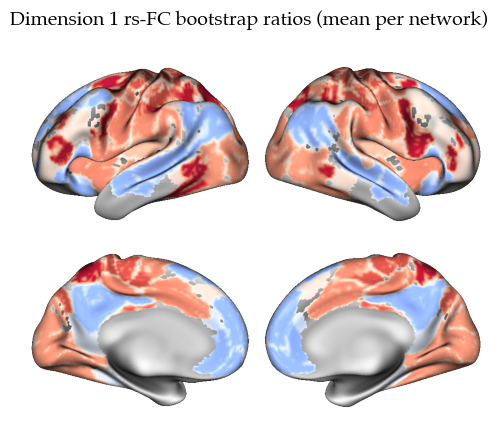

In [77]:
# Mean BR per network, all connections (unthresholded)
net_br = merged_df.groupby("atlas_value")["BR"].mean()

br_volume = np.zeros_like(data)
for atlas_val, mean_br in net_br.items():
    br_volume[data == atlas_val] = mean_br
br_img = nib.Nifti1Image(br_volume, affine, hdr)

vmax = np.abs(net_br).max()
fig = plot_surf(br_img, vmax=vmax, cmap="coolwarm")
fig.suptitle(f"Dimension {DIM} rs-FC bootstrap ratios (mean per network)", y=0.95, fontsize=14)
out = fig_dir / f"{RUN}_{BLOCK}_rsfc-BR_Dim{DIM}.png"
fig.savefig(out, dpi=300, bbox_inches="tight", facecolor="white", edgecolor="none")
print(f"✓ Saved {out}")
plt.show()

sizeof_hdr should be 348; set sizeof_hdr to 348


✓ Saved /Users/hampson/Desktop/struc-func-plsc/derivatives/figures/katie-y4-vars_rni_rsfc-BR_Dim1_thr2.5.png


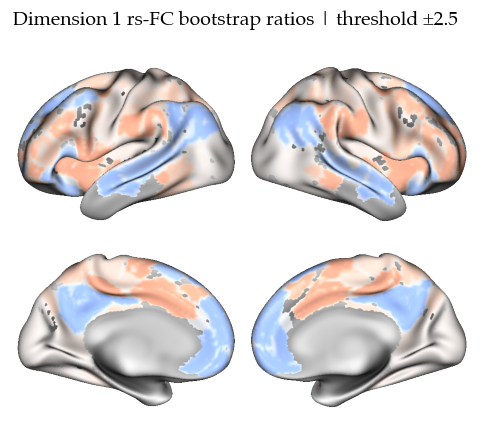

In [78]:
# Mean BR per network, only connections with |BR| > 2.5
BR_THR = 2.5
sig = merged_df[merged_df["BR"].abs() > BR_THR]
net_br_sig = sig.groupby("atlas_value")["BR"].mean()

br_volume = np.zeros_like(data)
for atlas_val, mean_br in net_br_sig.items():
    br_volume[data == atlas_val] = mean_br
br_img = nib.Nifti1Image(br_volume, affine, hdr)

vmax = np.abs(merged_df["BR"]).max()
fig = plot_surf(br_img, vmax=vmax, cmap="coolwarm")
fig.suptitle(f"Dimension {DIM} rs-FC bootstrap ratios | threshold ±{BR_THR}", y=0.95, fontsize=14)
out = fig_dir / f"{RUN}_{BLOCK}_rsfc-BR_Dim{DIM}_thr{BR_THR}.png"
fig.savefig(out, dpi=300, bbox_inches="tight", facecolor="white", edgecolor="none")
print(f"✓ Saved {out}")
plt.show()

## Plot LME

Primary LMEs from `2b-plsc-reg-boot.R`: latent score ~ measure + covariates, with
site/family random effects. The measure is z-scored in the model, so the x-axis is z-scored here too.
Each point is the mean latent score (± SE) at one response level of the measure; sparse levels are pooled so every bin has at least `MIN_N` people, and continuous measures are split into quantile bins.

In [79]:
plt.rcParams["font.family"] = "Palatino"
plt.rcParams["font.weight"] = "bold"

# LME results for every dimension that has them
res_files = sorted(REG_DIR.glob("plsc-reg-boot-dim*-results.csv"))
assert res_files, f"No LME results in {REG_DIR}"
lme_res = pd.concat([pd.read_csv(f) for f in res_files], ignore_index=True)

# latent scores (lx = rs-FC, ly = structure) + behaviour at the same visit
lx = pd.read_csv(plsc_dir / "rsfc_lx-scores.csv")
ly = pd.read_csv(plsc_dir / f"{BLOCK}_ly-scores.csv")
measures = pd.read_csv(run_dir / "lme-measures.csv")
reg_df = lx.merge(ly, on="participant_id").merge(measures, on="participant_id")

sig_res = lme_res[lme_res["significant_fdr05"]].sort_values(["dimension", "p_value"])
print(f"{len(sig_res)} of {len(lme_res)} LMEs survive FDR < .05")
sig_res[["dimension", "outcome", "predictor", "estimate", "ci_lower", "ci_upper", "p_value", "p_fdr"]]

27 of 180 LMEs survive FDR < .05


,dimension,outcome,predictor,estimate,ci_lower,ci_upper,p_value,p_fdr
13,dim1,score_lx,ders_distracted,0.003226,0.002231,0.004220,2.221032e-10,3.997858e-09
3,dim1,score_lx,bas_fun_seeking,-0.002072,-0.003051,-0.001093,3.371257e-05,3.034131e-04
23,dim1,score_ly,upps_pos_urgency,-0.004620,-0.006827,-0.002413,4.139518e-05,7.451132e-04
5,dim1,score_lx,upps_pos_urgency,-0.002007,-0.002988,-0.001027,6.088735e-05,3.653241e-04
31,dim1,score_ly,ders_distracted,0.004461,0.002185,0.006736,1.231758e-04,1.108582e-03
2,dim1,score_lx,bas_drive,-0.001914,-0.002898,-0.000931,1.369724e-04,6.163759e-04
0,dim1,score_lx,bis_sum,0.001727,0.000702,0.002751,9.572645e-04,3.446152e-03
10,dim1,score_lx,erq_suppression,-0.001502,-0.002484,-0.000519,2.751230e-03,8.253691e-03
20,dim1,score_ly,bas_drive,-0.003371,-0.005586,-0.001156,2.859528e-03,1.522916e-02
8,dim1,score_lx,upps_sens_seeking,-0.001487,-0.002476,-0.000498,3.224078e-03,8.290486e-03


In [80]:
# Helpers: bin each measure and summarise the latent score per bin
MIN_N = 30       # pool neighbouring response levels until each bin has at least this many people
MAX_LEVELS = 20  # measures with more distinct values than this are treated as continuous
N_QBINS = 10     # number of quantile bins for continuous measures

def score_col(row):
    # dim1 + score_lx -> lx_Dim1
    k = row["dimension"].replace("dim", "")
    return f"{row['outcome'].replace('score_', '')}_Dim{k}"

def make_bins(x):
    """Bin labels for x: one bin per response level (sparse levels pooled), or quantile bins."""
    if x.nunique() > MAX_LEVELS:
        return pd.qcut(x, N_QBINS, labels=False, duplicates="drop")
    counts = x.value_counts().sort_index()
    groups, cur, n = [], [], 0
    for level, c in counts.items():
        cur.append(level); n += c
        if n >= MIN_N:
            groups.append(cur); cur, n = [], 0
    if cur:  # leftover sparse top levels go into the last bin
        if groups: groups[-1] += cur
        else: groups.append(cur)
    level_to_bin = {lv: b for b, g in enumerate(groups) for lv in g}
    return x.map(level_to_bin)

def binned_means(x, y):
    d = pd.DataFrame({"x": x, "y": y, "bin": make_bins(x)})
    return d.groupby("bin").agg(x=("x", "mean"), mean=("y", "mean"),
                                se=("y", lambda v: v.std() / np.sqrt(len(v))), n=("y", "size"))

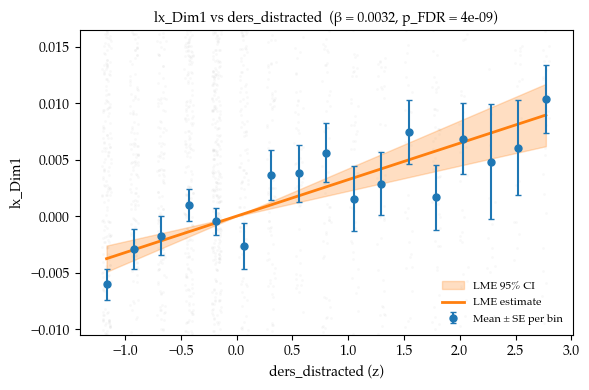

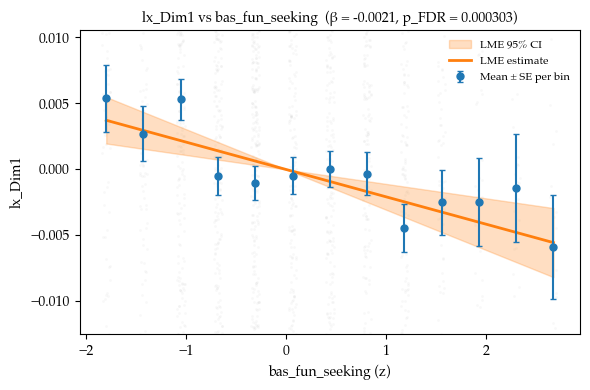

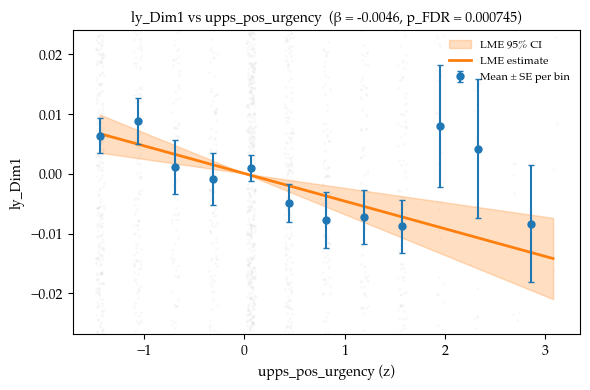

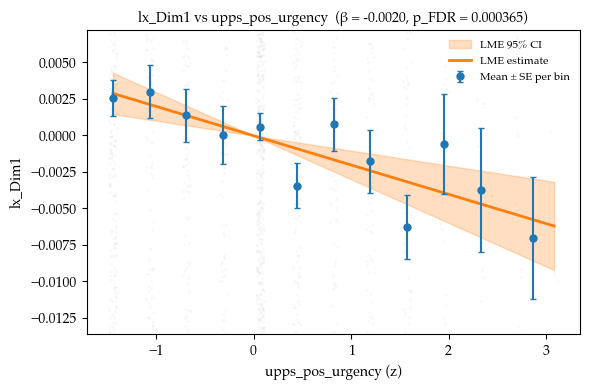

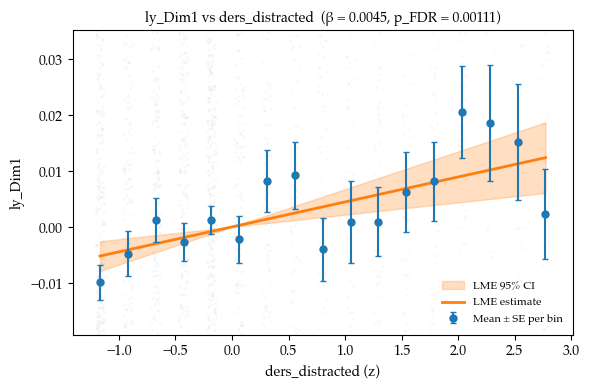

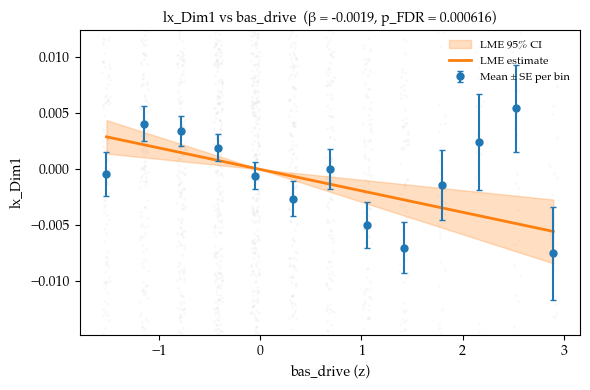

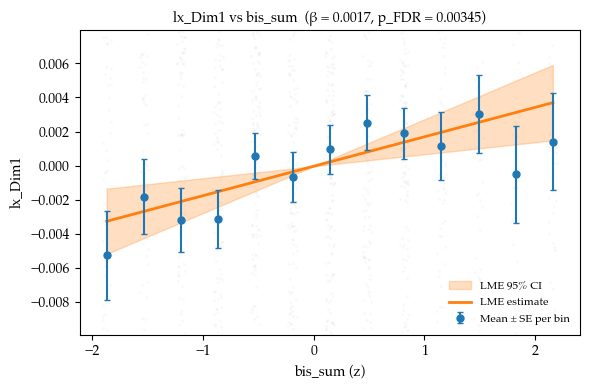

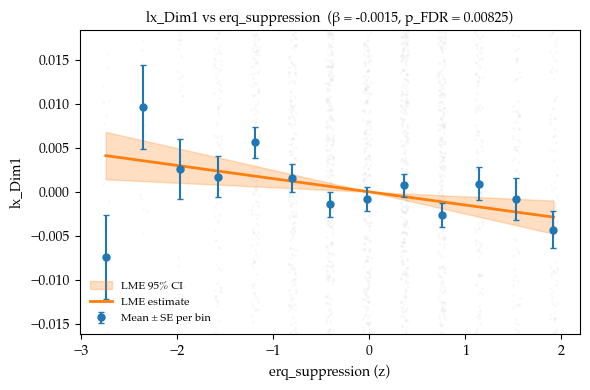

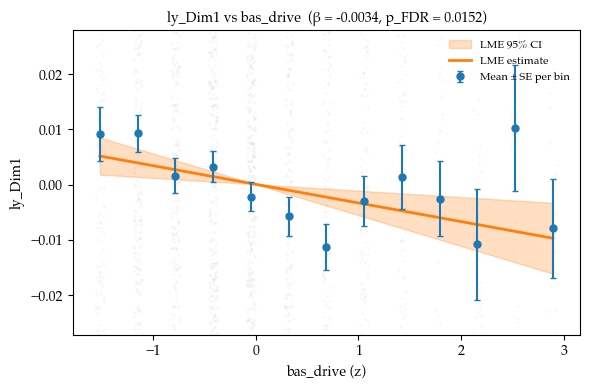

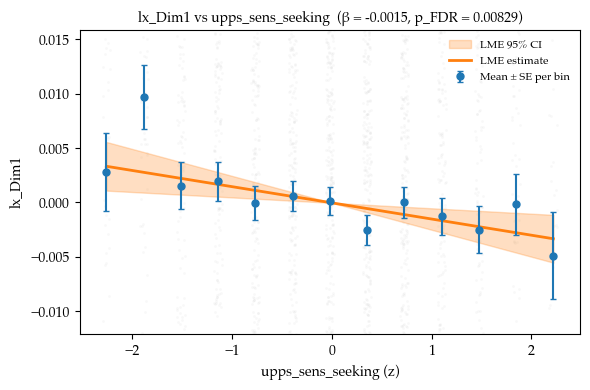

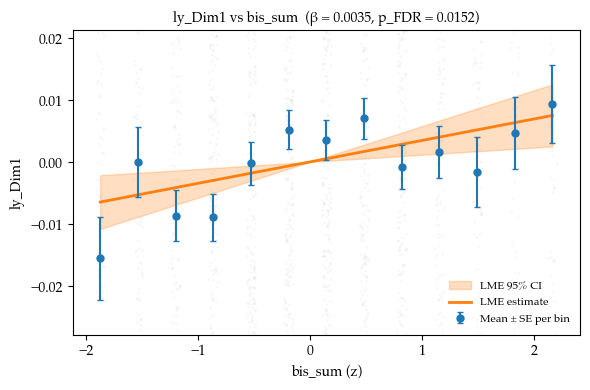

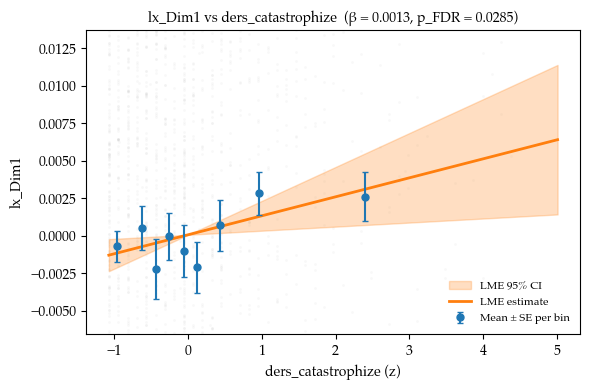

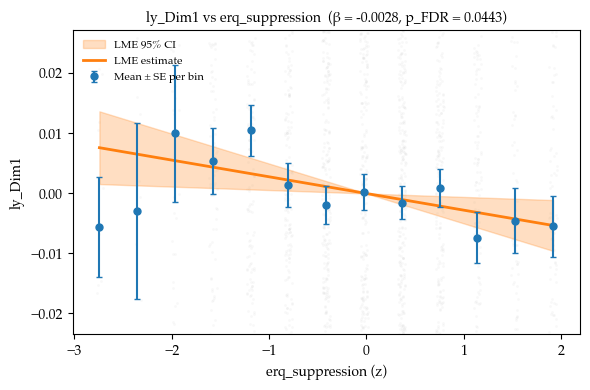

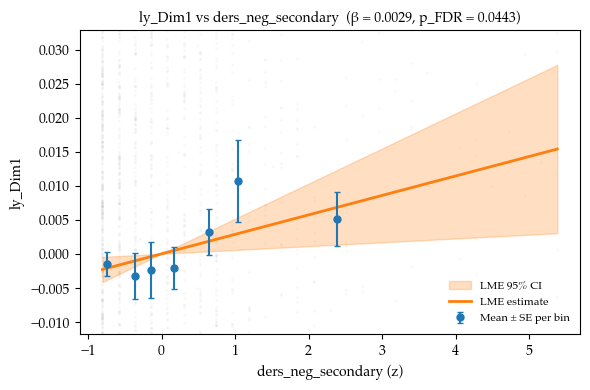

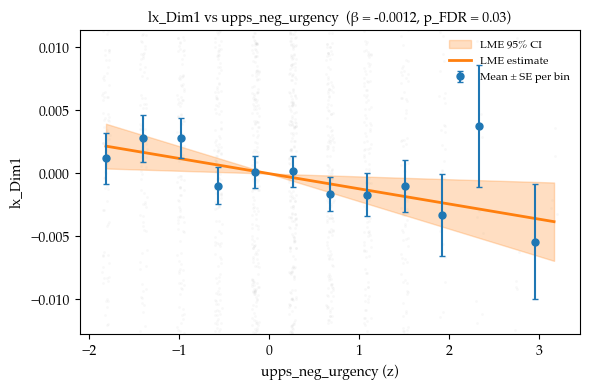

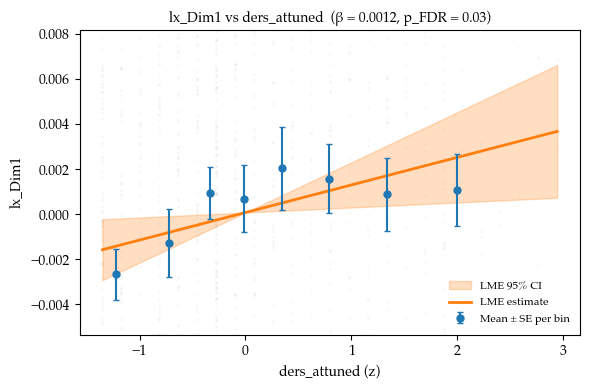

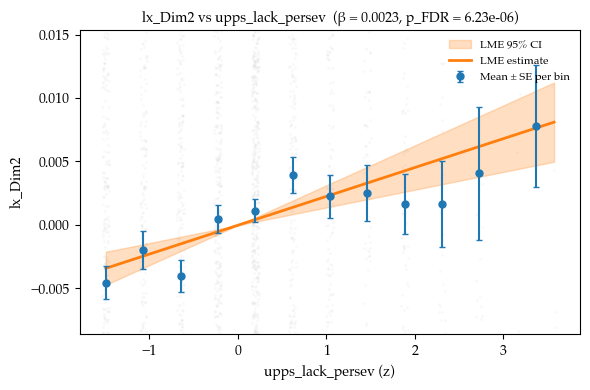

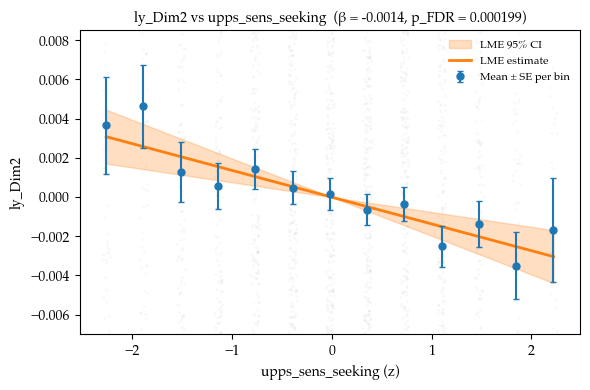

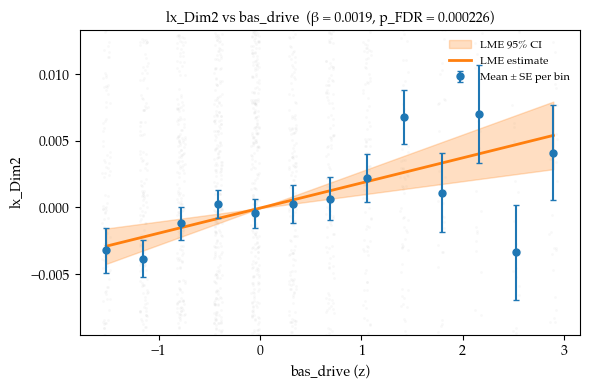

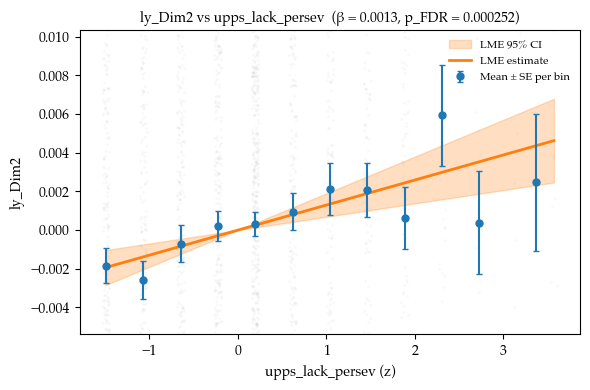

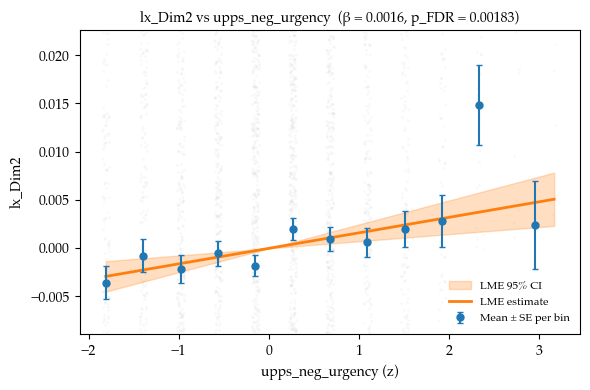

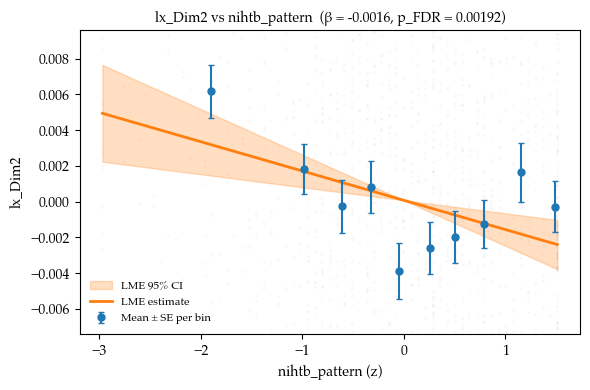

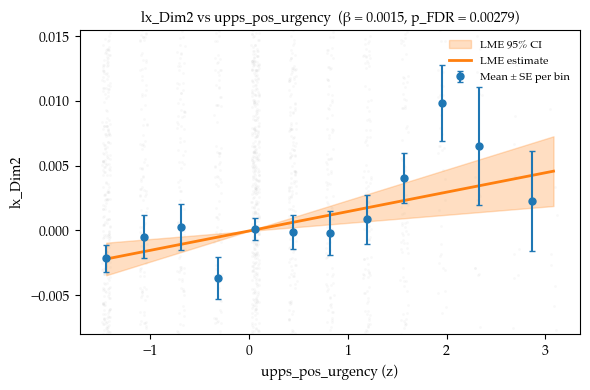

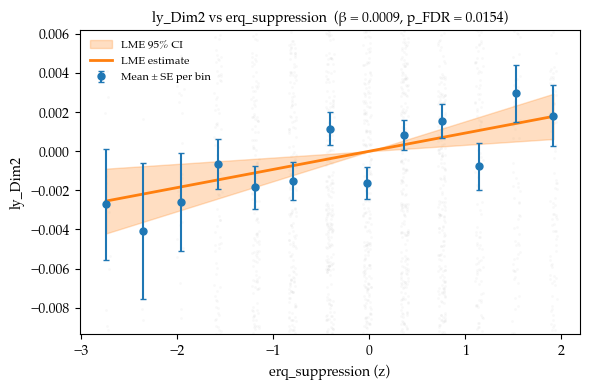

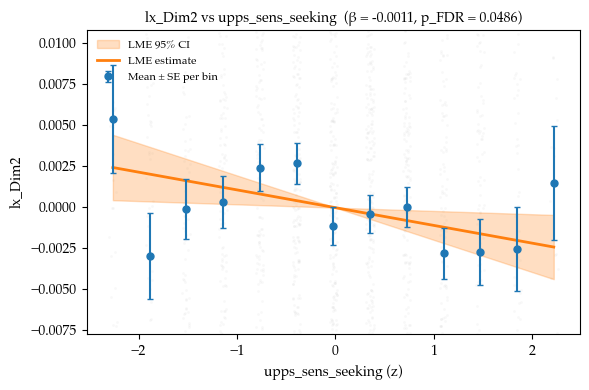

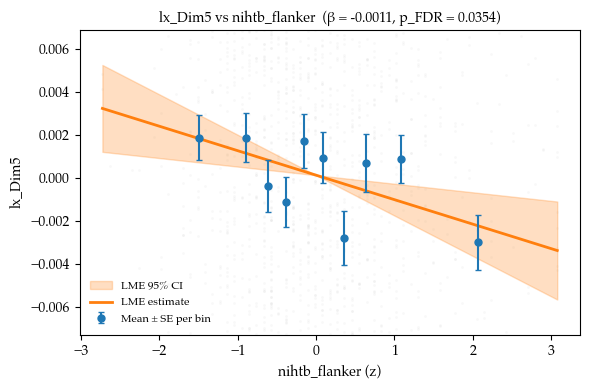

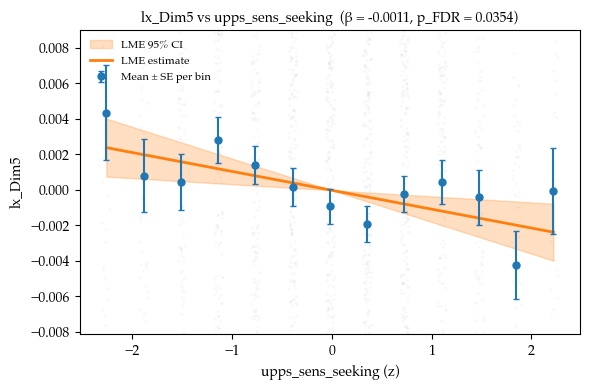

In [81]:
# Binned means (± SE) with the LME estimate and 95% CI, for each FDR-significant LME.
# The LME line is drawn through the overall mean score, since the model intercept is at the
# covariate means rather than on the raw score scale. Raw points are shown faintly behind;
# the y-axis is zoomed to the binned means, so most raw points fall outside it.
rng = np.random.default_rng(0)

for _, row in sig_res.iterrows():
    ycol, xcol = score_col(row), row["predictor"]
    d = reg_df[[xcol, ycol]].dropna()
    x = (d[xcol] - d[xcol].mean()) / d[xcol].std()
    y = d[ycol]
    bm = binned_means(x, y)

    x_vals = np.linspace(x.min(), x.max(), 100)
    y0 = y.mean()
    lme_line = y0 + row["estimate"] * x_vals
    lo, hi = y0 + row["ci_lower"] * x_vals, y0 + row["ci_upper"] * x_vals

    fig, ax = plt.subplots(figsize=(6, 4))
    jitter = rng.uniform(-0.04, 0.04, len(x)) if x.nunique() <= MAX_LEVELS else 0
    ax.scatter(x + jitter, y, s=4, alpha=0.05, color="gray", linewidths=0, zorder=1)
    ax.fill_between(x_vals, lo, hi, color="tab:orange", alpha=0.25, label="LME 95% CI", zorder=2)
    ax.plot(x_vals, lme_line, "-", color="tab:orange", linewidth=2, label="LME estimate", zorder=3)
    ax.errorbar(bm["x"], bm["mean"], yerr=bm["se"], fmt="o", color="tab:blue",
                markersize=5, capsize=2, label="Mean ± SE per bin", zorder=4)

    # zoom to the binned means and the LME line
    top = np.nanmax(np.r_[bm["mean"] + bm["se"], hi, lo])
    bot = np.nanmin(np.r_[bm["mean"] - bm["se"], hi, lo])
    pad = 0.15 * (top - bot)
    ax.set_ylim(bot - pad, top + pad)

    ax.set_xlabel(f"{xcol} (z)", weight="bold")
    ax.set_ylabel(ycol, weight="bold")
    ax.set_title(f"{ycol} vs {xcol}  (β = {row['estimate']:.4f}, p_FDR = {row['p_fdr']:.3g})",
                 weight="bold", fontsize=10)
    ax.legend(fontsize=8, frameon=False)
    fig.tight_layout()
    out = fig_dir / f"{RUN}_{BLOCK}_lme_{row['dimension']}_{ycol}_{xcol}.png"
    fig.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()